# Noise-Scheduler Test. 

Testung von einem Forward-Prozess: Standardisierte Embeddings -> Verrauschte Embeddings -> Denoising mit Dummy-Transformer. 



Theorie: Für $q_{sample}$ muss die Varianzerhaltung, wie der Energieerhaltungssatz gelten: 
$$x_t = \sqrt{\bar\alpha_t}\, x_0 + \sqrt{1-\bar\alpha_t}\ \varepsilon$$

Beide Koeffizienten sind Katheten eines Einheitskreises   $ (\sqrt{\bar\alpha_t})^2 + (\sqrt{1-\bar\alpha_t})^2 = \bar\alpha_t + (1-\bar\alpha_t) = 1$

Es ergeben sich als Testbedingungen: 
- $\bar\alpha_t$ muss monoton fallen von 1 auf 0 bei $t$ =0 
- bei t = 0 muss $x_t = x_0$ sein 
- Wenn $x_0$ selbst Standardnormal ist, muss std($x_t$) = 1 für jedes t sein



### Unterm Strich:
Der eigentliche Vorteil von Diffusion gegenüber GANs/VAEs: ein unlösbar schweres Problem („erzeuge ein Peptid aus dem Nichts”) wird in 1000 leichte, stabile Regressionsprobleme zerlegt („mach dieses Ding ein bisschen weniger verrauscht”). Jedes einzelne ist ein simpler L2-Fit — kein Min-Max-Spiel wie beim GAN, kein Mode Collapse, kein Balancieren zweier Netze. Die Stochastik in $t$ und $\varepsilon$ ist das Mittel, mit dem diese Zerlegung trainiert wird, nicht der Vorteil selbst. Nachteil: 1000 Forward-Passes beim Sampling statt einem.


In [93]:
import torch 
import matplotlib.pyplot as plt
from aguirre.diffusion import NoiseSchedule, DiffusionProcess
from aguirre.config import Config
import numpy as np
import torch.nn as nn

tensor([9.9996e-01, 2.4288e-09])


/var/folders/bd/jt99k0p569j1j60f7kqyhhyr0000gn/T/ipykernel_24432/1684980683.py:19: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


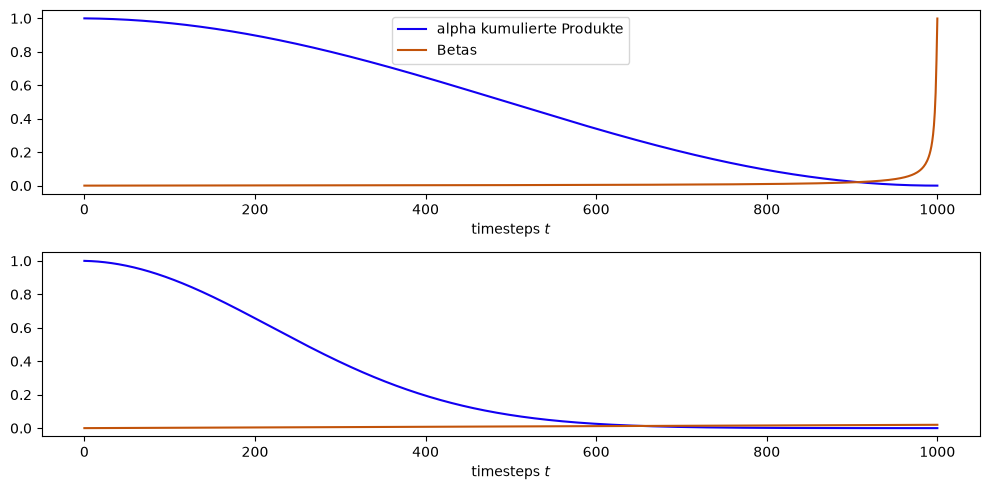

In [28]:
#==Kumulierte Alphas und Betas vergleichen==
steps = 1000
t = np.linspace(0, steps, steps)
sched_cosine = NoiseSchedule(timesteps= steps, beta_schedule= "cosine")
sched_linear = NoiseSchedule(timesteps= steps, beta_schedule= "linear")

print(sched_cosine.alphas_cumprod[[0, -1]])

fig, ax = plt.subplots(2,1, figsize = (10, 5))
ax[0].plot(t, sched_cosine.alphas_cumprod, label= "alpha kumulierte Produkte", color = "#1200f2")
ax[0].plot(t,sched_cosine.betas, label = "Betas", color = "#c2530a")
ax[0].set_xlabel("timesteps $t$")

ax[1].plot(t, sched_linear.alphas_cumprod, label= "alpha kumulierte Produkte", color = "#1200f2")
ax[1].plot(t,sched_linear.betas, label = "Betas", color = "#c2530a")
ax[1].set_xlabel("timesteps $t$")
ax[0].legend(loc='upper center')
fig.tight_layout()
fig.show()




In [33]:
#==Monotonie==

torch.all(sched_cosine.alphas_cumprod.diff() < 0)

tensor(True)

In [ ]:
#==Extrakt und Buffer-Test==

t = torch.tensor([0, 500, 999]) #3 Zeitpunkte t
x_shape = (3, 14, 320) #Dummy-Shape für Vektorfeld
out = NoiseSchedule.extract(sched_cosine.alphas_cumprod, t, x_shape) # Nimmt aus dem cumprod zu dem Zeitpunkten t  heraus und passt es an die x dimension an

print(out.shape)

torch.Size([3, 1, 1])


Merksatz fürs ganze Projekt: t.shape[0] muss immer gleich x.shape[0] sein.

In [ ]:
t_probe = [0, 1, 10, 100, 500, 999]
cfg = Config(embed_dim=320, pep_max_len=14)
proc = DiffusionProcess(model=None, cfg= cfg)

x0 = torch.randn(256, 14, 320)
#torch.manual_seed(cfg.seed)
for t_p in t_probe:
    t = torch.full((256,), t_p, dtype=torch.long)  
    x_t = proc.q_sample(x_start= x0,t = t)
    print(f"|Mittelwert {x_t.mean().item(): 12.5f} || Standardabweichung: {x_t.std().item():<3.2f} |")
    per_dim = x_t.std(dim=(0, 1))       # (320,)
    print(per_dim.min().item(), per_dim.max().item(), per_dim.mean().item()) # Muss alles nahe 1 sein





|Mittelwert     -0.00043 || Standardabweichung: 1.00 |
0.958666205406189 1.0302406549453735 0.9994619488716125
|Mittelwert     -0.00042 || Standardabweichung: 1.00 |
0.9583215117454529 1.0302071571350098 0.9994489550590515
|Mittelwert     -0.00048 || Standardabweichung: 1.00 |
0.9593462944030762 1.0305626392364502 0.9994329214096069
|Mittelwert     -0.00031 || Standardabweichung: 1.00 |
0.9590766429901123 1.0325058698654175 0.9994539022445679
|Mittelwert     -0.00006 || Standardabweichung: 1.00 |
0.9664638638496399 1.037352442741394 1.0000180006027222
|Mittelwert      0.00003 || Standardabweichung: 1.00 |
0.9656391739845276 1.0324225425720215 1.0001662969589233


Std bleibt also über alle $x_t$ gleich und wird über die Embeddingdimensionen gebildet.


### Der Dummy-Denoiser.
Bauen eines Denoiser, dessen Lossfunktion einfach zu berechnen ist. Ein Modell, dass Konstant 0 ausgibt führt zur validierbarkeit des Noise-Schedulers:





$$\mathcal{L} = \mathbb{E}[(0 - x_0)^2] = \mathbb{E}[x_0^2] = \mathrm{Var}(x_0) = 1$$



In [ ]:
class ZeroDenoiser(nn.Module):
    def forward(self, x,t, padding_mask = None):
        return torch.zeros_like(x)


proc = DiffusionProcess(model=ZeroDenoiser(), cfg=cfg)
loss = proc(x0, padding_mask=torch.zeros(256, 14, dtype=torch.bool))

print(loss)



tensor(1.0001)

Mit Padding: Erwartung: False → ≈0,5 · True → ≈1,0. Der Faktor 2 ist exakt der Padding-Anteil.

In [96]:
B, L, D = 256, 14, cfg.embed_dim

# Maske: vordere 7 Positionen echt, hintere 7 Padding
padding_mask = torch.zeros(B, L, dtype=torch.bool)
padding_mask[:, 7:] = True                      # (B, L)

# x0 passend dazu: Padding-Positionen auf 0
x0 = torch.randn(B, L, D)
x0[:, 7:, :] = 0.0                              # (B, L, D)


for flag in (False, True):
    cfg = Config(embed_dim=D, pep_max_len=L, mask_loss=flag)
    proc = DiffusionProcess(model=ZeroDenoiser(), cfg=cfg)
    loss = proc(x0, padding_mask=padding_mask)
    print(f"mask_loss={flag}: {loss.item():.4f}")

mask_loss=False: 0.4998
mask_loss=True: 0.9997


Für echten Run: Paddingmaske aus DataCoordinator längentensor. 
mask_loss = False  nur bei vergleich mit Torres. Für unser Modell mask_Loss = True, sonst Attention leakage

Inferenz: Länge wird durch Ziehen aus Datanlängenverteilung gezogen. 

### 5d - Lernfaehigkeits-Test mit echten AMPs

Bisher war `x0` synthetisches `randn`. Jetzt der Durchlauf mit echten Daten:
10 zufaellige Peptide aus `torres_train_sequences.csv`, durch den ESMWrapper
encodiert und mit den 8M-Standards standardisiert.

Zweck: pruefen, ob der Gradientenpfad durch `DiffusionProcess` zum Denoiser
durchlaeuft. Bricht der Loss hier nicht ein, ist die Kette unterbrochen --
und das will man wissen, bevor der Transformer dran ist.

In [99]:
#== Imports und Config fuer den echten Durchlauf ==
import pandas as pd
import torch
import torch.nn as nn

from aguirre.config import Config, TRACKED_DIR
from aguirre.esm_wrapper import ESMWrapper
from aguirre.diffusion import DiffusionProcess

cfg_real = Config(
    esm_model_name = "esm2_t6_8M_UR50D",
    embed_dim      = 320,
    pep_max_len    = 14,
    mask_loss      = True,
)
print("device:", cfg_real.device)

device: mps


In [100]:
#== 10 zufaellige AMPs ziehen ==
df = pd.read_csv(TRACKED_DIR / "torres_train_sequences.csv")

seqs = df["sequence"].dropna().astype(str).str.upper()
seqs = seqs[seqs.str.len() <= cfg_real.pep_max_len]
# nur kanonische Aminosaeuren, sonst stolpert spaeter der Decoder ueber X/B/U/Z
#seqs = seqs[~seqs.str.contains(f"[^{cfg_real.AS_alphabet}]", regex=True)]

seqs = seqs.sample(10, random_state=42).tolist()
for s in seqs:
    print(f"{len(s):3d}  {s}")

 12  VRLRKRVAVIRA
 13  SSLLEKGLDGAKK
  6  ILIKRK
  4  RRKK
 12  FIHKLVHKHVLF
 11  GLFDIIKKVAS
 12  VRLRIRNAVIRA
 13  ILPWKWPPWPWRR
 12  RWWKIWVIRYWR
  9  VWRRKKYWR


In [101]:
#== Encodieren ==
wrapper = ESMWrapper(cfg_real)
emb, lengths = wrapper.encode(seqs)          # (B, L_max, D), list[int]
lengths = torch.tensor(lengths)              # (B,)

print("emb    :", tuple(emb.shape))
print("lengths:", lengths.tolist())

emb    : (10, 14, 320)
lengths: [12, 13, 6, 4, 12, 11, 12, 13, 12, 9]


In [102]:
#== Standardisieren (pro Embedding-Dimension) + Padding-Maske ==
standards = pd.read_csv(TRACKED_DIR / "standards_8M.csv")
mu    = torch.tensor(standards["mean"].to_numpy(), dtype=torch.float32)   # (D,)
sigma = torch.tensor(standards["std"].to_numpy(),  dtype=torch.float32)   # (D,)

# True = Padding  (PyTorch-Konvention, >= statt < invertiert direkt in der Bedingung)
positions    = torch.arange(cfg_real.pep_max_len)                 # (L,)
padding_mask = positions[None, :] >= lengths[:, None]             # (B, L)
valid        = ~padding_mask                                      # (B, L)

x0 = (emb - mu) / sigma                                           # (B, L, D)
x0 = x0 * valid.unsqueeze(-1)                                     # Padding wieder auf 0

gueltig = x0[valid]                                               # (N_valid, D)
per_dim = gueltig.std(dim=0)                                      # (D,)
print(f"Std gesamt (nur gueltige Positionen): {gueltig.std().item():.4f}   (erwartet ~1)")
print(f"pro Dimension  min {per_dim.min().item():.3f}   max {per_dim.max().item():.3f}   "
      f"mean {per_dim.mean().item():.3f}")

Std gesamt (nur gueltige Positionen): 0.8559   (erwartet ~1)
pro Dimension  min 0.468   max 1.151   mean 0.772


#### Test A - Gradientenpfad (fixes t, fixes eps)

Mit festem Zeitschritt und festem Rauschen ist das Ziel deterministisch: ein
reiner Overfit-Test auf 10 Peptiden. `nn.Linear(320, 320)` hat 102k Parameter
fuer 500 Token -- es ist massiv ueberparametrisiert und **muss** den Loss
deutlich druecken. Tut es das nicht, ist der Gradient unterbrochen.

In [104]:
class LinearDenoiser(nn.Module):
    """Wegwerf-Denoiser: ignoriert t, mappt jede Position einzeln."""

    def __init__(self, d: int):
        super().__init__()
        self.layer = nn.Linear(d, d)

    def forward(self, x, t, padding_mask=None):
        return self.layer(x)                 # (B, L, D)


torch.manual_seed(0)
proc = DiffusionProcess(model=LinearDenoiser(d=cfg_real.embed_dim), cfg=cfg_real)
opt  = torch.optim.Adam(proc.model.parameters(), lr=1e-3)   # Klammern! parameters ist eine Methode

t_fix     = torch.full((x0.shape[0],), 100, dtype=torch.long)   # (B,)
noise_fix = torch.randn_like(x0)                                # (B, L, D)

for step in range(501):
    opt.zero_grad()
    loss = proc.p_losses(x0, t_fix, padding_mask=padding_mask, noise=noise_fix)
    loss.backward()
    opt.step()
    if step % 100 == 0:
        print(f"step {step:4d}   loss {loss.item():.4f}")

step    0   loss 0.9669
step  100   loss 0.0239
step  200   loss 0.0077
step  300   loss 0.0032
step  400   loss 0.0014
step  500   loss 0.0007


#### Test B - realistischer Durchlauf (zufaelliges t, zufaelliges eps)

Jetzt ueber `forward()`, also wie im echten Training: jedes Peptid zieht pro
Schritt ein neues t und ein neues eps.

Erwartung ist hier ausdruecklich **kein** Absturz gegen 0. Das lineare Modell
sieht t nicht und muss deshalb einen Kompromiss ueber alle Rauschstaerken
finden -- der optimale Schaetzer waere eine t-abhaengige Schrumpfung. Der Loss
faellt von ~1,0 auf ein Plateau und bleibt verrauscht. Genau diese Luecke ist
die Daseinsberechtigung des Transformers mit Zeit-Embedding.

step    0   loss 0.9983
step  100   loss 0.2247
step  200   loss 0.3043
step  300   loss 0.2840
step  400   loss 0.2003
step  500   loss 0.1876


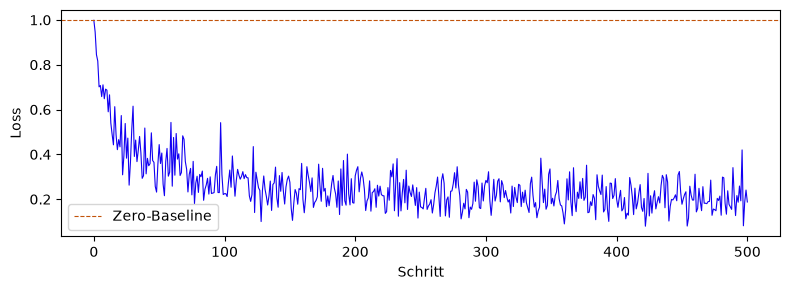

In [105]:
torch.manual_seed(0)
proc_b = DiffusionProcess(model=LinearDenoiser(cfg_real.embed_dim), cfg=cfg_real)
opt_b  = torch.optim.Adam(proc_b.model.parameters(), lr=1e-3)

verlauf = []
for step in range(501):
    opt_b.zero_grad()
    loss = proc_b(x0, padding_mask=padding_mask)     # forward(): zieht t selbst
    loss.backward()
    opt_b.step()
    verlauf.append(loss.item())
    if step % 100 == 0:
        print(f"step {step:4d}   loss {loss.item():.4f}")

import matplotlib.pyplot as plt
plt.figure(figsize=(8, 3))
plt.plot(verlauf, lw=0.8, color="#1200f2")
plt.axhline(1.0, ls="--", lw=0.8, color="#c2530a", label="Zero-Baseline")
plt.xlabel("Schritt"); plt.ylabel("Loss"); plt.legend(); plt.tight_layout()